# SECOM — Data Understanding & Data Preparation (Steps 1–2)

**CRISP-DM phases covered:** Business Understanding → Data Understanding → Data Preparation
(rough feature reduction, outlier treatment).

| Section | Content |
|---|---|
| 1 | Background of the dataset; what rows and columns mean |
| 2 | Descriptive statistics; target coding; class balance |
| 3 | Missing-value audit: are *all* missing values flagged as missing? |
| 4 | Stratified 80/20 train/test split; the test set is sealed and put aside |
| 5 | Rough feature reduction **(training set only)**: constant features, features with many N/As |
| 6 | Correlation heatmap (visualise only; nothing removed) |
| 7 | Outliers with the 3σ rule: options, decision, implementation |
| 8 | Summary of the preparation funnel and saved state |

Every preparation step ends with a **Step Impact Protocol (SIP) table**: the options, their
pros and cons, the decision made, and its consequence. The numbers in the SIP tables are
computed in the notebook, not typed by hand. Each decision is also logged in
`docs/scientific_diary.md`.

> **Ground rule:** after Section 4 the test set is **never loaded again** in this notebook.
> Every statistic, threshold and boundary from Section 5 onward comes from the training set.

In [1]:
from pathlib import Path
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.spatial.distance import squareform
from sklearn.model_selection import train_test_split

from secom_analysis.data import load_labels, load_secom, resolve_data_dir
from secom_analysis.preparation import (
    cap_outliers, flag_outliers, missing_percentage, missing_threshold_pareto,
    remove_outliers, save_split, save_state, sip_table, three_sigma_bounds,
    verify_sealed, zero_variance_features,
)

warnings.filterwarnings("ignore", category=RuntimeWarning)
ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
DATA_DIR = resolve_data_dir(ROOT / "data" / "raw")
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42
TEST_SIZE = 0.20

# Chart style: two fixed series colours (blue = pass / kept, orange = fail / removed),
# recessive grid, no top/right spines.
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#7b7a75"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": "#ecebe7",
    "axes.axisbelow": True, "axes.edgecolor": MUTED, "axes.labelcolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10,
})
pd.set_option("display.max_columns", 30, "display.width", 140)

def savefig(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / name, bbox_inches="tight")
    plt.show()

print("data:", DATA_DIR)

data: /home/bnam/Desktop/Warehouse/SECOM/data/raw/secom (1)


## 1. Background of the dataset

**Source.** SECOM (*SEmiCOnductor Manufacturing*), UCI Machine Learning Repository, donated
in 2008 by Michael McCann and Adrian Johnston.

**Process.** Modern semiconductor fabrication is monitored continuously. Sensors and
process measurement points on the line record hundreds of signals per production entity.
Engineers have far more signals than they need. Some carry useful information, many are
irrelevant, and many are noise. The business goal is **feature selection**: find the
signals that drive yield excursions (failures in in-house line testing), so engineers can
monitor fewer signals, learn faster, raise throughput and cut cost per unit.

**What the files mean**

| File | Content |
|---|---|
| `secom.data` | 1,567 rows × 590 columns of real-valued measurements, space-separated; missing values written as `NaN` |
| `secom_labels.data` | 1,567 rows: the pass/fail label (−1 / 1) and the date-time stamp of the test |
| `secom.names` | Dataset description |

- **One row** = one production entity (a wafer or lot) that went through the line and
  was tested in house. Row *i* of the data file belongs to row *i* of the label file.
- **One column** = one sensor or process-measurement signal. Columns are **anonymised**:
  there are no names and no units, only positions, which we call `feature_000` …
  `feature_589`. So we can't use domain knowledge per feature. Every decision has to be
  driven by the data.
- **Target** = the yield outcome of in-house line testing (pass or fail), with a timestamp.

In [2]:
names = (DATA_DIR / "secom.names").read_text(encoding="utf-8").splitlines()
for line in names:
    if any(key in line for key in ("Number of Instances", "Number of Attributes",
                                   "Attribute Characteristics", "Missing Values",
                                   "Date Donated", "Associated Tasks")):
        print(line.strip())

X, y = load_secom(DATA_DIR)          # features (NaN = missing) and target (0 = pass, 1 = fail)
labels = load_labels(DATA_DIR)       # raw label (-1/1) and timestamp
print(f"\nfeatures: {X.shape[0]:,} rows x {X.shape[1]} columns   labels: {labels.shape[0]:,} rows")
print("The .names file counts 591 attributes = 590 measurements + 1 label.")
X.iloc[:5, :10]

Number of Instances: 1567
Attribute Characteristics: Real
Number of Attributes: 591
Date Donated: 2008-11-19
Associated Tasks: Classification, Causal-Discovery
Missing Values? Yes

features: 1,567 rows x 590 columns   labels: 1,567 rows
The .names file counts 591 attributes = 590 measurements + 1 label.


,feature_000,feature_001,feature_002,feature_003,feature_004,feature_005,feature_006,feature_007,feature_008,feature_009
0,3030.93,2564.00,2187.7333,1411.1265,1.3602,100.0,97.6133,0.1242,1.5005,0.0162
1,3095.78,2465.14,2230.4222,1463.6606,0.8294,100.0,102.3433,0.1247,1.4966,-0.0005
2,2932.61,2559.94,2186.4111,1698.0172,1.5102,100.0,95.4878,0.1241,1.4436,0.0041
3,2988.72,2479.90,2199.0333,909.7926,1.3204,100.0,104.2367,0.1217,1.4882,-0.0124
4,3032.24,2502.87,2233.3667,1326.5200,1.5334,100.0,100.3967,0.1235,1.5031,-0.0031


## 2. Descriptive statistics

### 2.1 Coding of defective and good wafers

In [3]:
coding = pd.DataFrame({
    "raw code (secom_labels.data)": [-1, 1],
    "meaning": ["pass: good wafer", "fail: defective wafer"],
    "coded as `defective`": [0, 1],
})
counts = labels["label"].value_counts()
coding["count"] = coding["raw code (secom_labels.data)"].map(counts)
coding["percentage"] = (coding["count"] / coding["count"].sum() * 100).round(2)
display(coding.style.hide(axis="index"))

defect_pct = y.mean() * 100
ratio = (1 - y.mean()) / y.mean()
print(f"Defective wafers: {int(y.sum())} of {len(y):,} = {defect_pct:.2f} %")
print(f"Imbalance ratio good : defective = {ratio:.1f} : 1")
print(f"Accuracy of a model that always predicts 'pass': {100 - defect_pct:.2f} %")

raw code (secom_labels.data),meaning,coded as `defective`,count,percentage
-1,pass: good wafer,0,1463,93.360000
1,fail: defective wafer,1,104,6.640000


Defective wafers: 104 of 1,567 = 6.64 %
Imbalance ratio good : defective = 14.1 : 1
Accuracy of a model that always predicts 'pass': 93.36 %


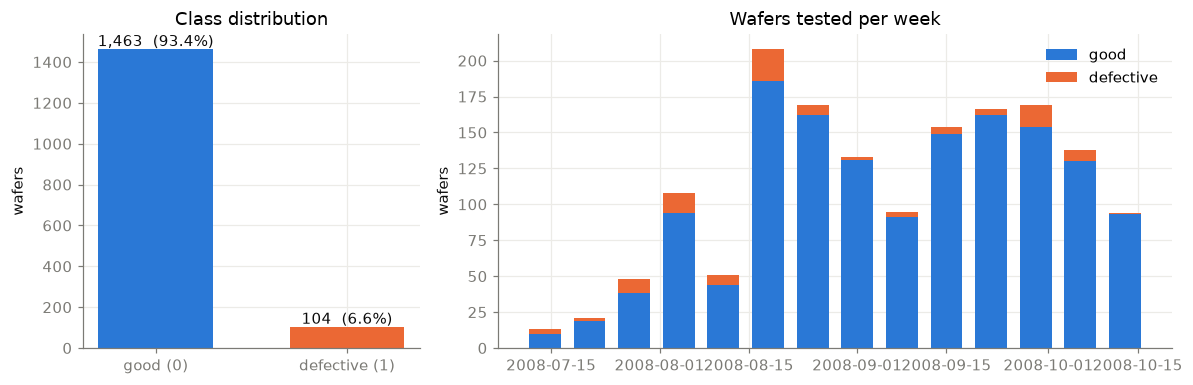

Production window: 2008-07-19 to 2008-10-17


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1, 2]})
bars = axes[0].bar(["good (0)", "defective (1)"], [int((y == 0).sum()), int(y.sum())],
                   color=[BLUE, ORANGE], width=0.6)
for bar, value in zip(bars, [(y == 0).mean(), y.mean()]):
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 15,
                 f"{bar.get_height():,.0f}  ({value:.1%})", ha="center", color=INK)
axes[0].set(title="Class distribution", ylabel="wafers")

weekly = labels.assign(week=labels["timestamp"].dt.to_period("W").dt.start_time,
                       fail=labels["label"].eq(1)).groupby("week")["fail"].agg(["size", "sum"])
axes[1].bar(weekly.index, weekly["size"] - weekly["sum"], width=5, color=BLUE, label="good")
axes[1].bar(weekly.index, weekly["sum"], width=5, bottom=weekly["size"] - weekly["sum"],
            color=ORANGE, label="defective")
axes[1].set(title="Wafers tested per week", ylabel="wafers")
axes[1].legend(frameon=False)
savefig(fig, "01_class_distribution.png")
print(f"Production window: {labels['timestamp'].min():%Y-%m-%d} to {labels['timestamp'].max():%Y-%m-%d}")

### 2.2 Is the dataset balanced? Why?

**No, it is strongly imbalanced.** About 93.4% of wafers are good and 6.6% defective,
roughly **14 good wafers for every defective one**.

**Why.** It reflects reality. A semiconductor line runs under tight statistical process
control, so failures are rare *by design*. If defects were as common as passes, the
process would not be economic. The imbalance is not a sampling artefact. It is the yield
of the process.

**Consequences for the project**
- **Accuracy is misleading.** A model that always says "pass" scores about 93% accuracy
  while catching zero defects. We will evaluate with recall on defective wafers, PR-AUC
  and balanced accuracy.
- **Splits must preserve the minority share.** With only 104 defective wafers, a careless
  split can leave the test set with too few defects to measure anything (Section 4).
- **Balancing** (e.g. SMOTE) is a later step, and is applied to training data only.

### 2.3 Descriptive statistics of the measurements

In [5]:
desc = X.describe().T
desc["missing_pct"] = X.isna().mean() * 100
desc["range"] = desc["max"] - desc["min"]
display(desc.head(10).round(4))

overview = pd.Series({
    "rows": X.shape[0],
    "columns": X.shape[1],
    "missing cells": int(X.isna().sum().sum()),
    "missing cells %": round(X.isna().mean().mean() * 100, 2),
    "columns without missing values": int(X.notna().all().sum()),
    "rows without missing values": int(X.notna().all(axis=1).sum()),
    "columns with zero variance (full data)": int(X.var().eq(0).sum()),
    "smallest column std (non-zero)": float(desc.loc[desc["std"] > 0, "std"].min()),
    "largest column std": float(desc["std"].max()),
    "columns with |skew| > 2": int(X.skew().abs().gt(2).sum()),
}, name="value", dtype=object)
display(overview.to_frame())

,count,mean,std,min,25%,50%,75%,max,missing_pct,range
feature_000,1561.0,3014.4529,73.6218,2743.2400,2966.2600,3011.4900,3056.6500,3356.3500,0.3829,613.1100
feature_001,1560.0,2495.8502,80.4077,2158.7500,2452.2475,2499.4050,2538.8225,2846.4400,0.4467,687.6900
feature_002,1553.0,2200.5473,29.5132,2060.6600,2181.0444,2201.0667,2218.0555,2315.2667,0.8934,254.6067
feature_003,1553.0,1396.3766,441.6916,0.0000,1081.8758,1285.2144,1591.2235,3715.0417,0.8934,3715.0417
feature_004,1553.0,4.1970,56.3555,0.6815,1.0177,1.3168,1.5257,1114.5366,0.8934,1113.8551
feature_005,1553.0,100.0000,0.0000,100.0000,100.0000,100.0000,100.0000,100.0000,0.8934,0.0000
feature_006,1553.0,101.1129,6.2372,82.1311,97.9200,101.5122,104.5867,129.2522,0.8934,47.1211
feature_007,1558.0,0.1218,0.0090,0.0000,0.1211,0.1224,0.1238,0.1286,0.5743,0.1286
feature_008,1565.0,1.4629,0.0739,1.1910,1.4112,1.4616,1.5169,1.6564,0.1276,0.4654
feature_009,1565.0,-0.0008,0.0151,-0.0534,-0.0108,-0.0013,0.0084,0.0749,0.1276,0.1283


,value
rows,1567
columns,590
missing cells,41951
missing cells %,4.54
columns without missing values,52
rows without missing values,0
columns with zero variance (full data),116
smallest column std (non-zero),0.000104
largest column std,6553.569317
columns with |skew| > 2,269


**Reading the table**
- The columns live on **very different scales**. Standard deviations range from about
  10⁻⁴ to several thousand. Any distance-based method (KNN imputation, SMOTE, etc.)
  needs scaling first.
- Many columns are **heavily skewed**. This matters for the outlier rule in Section 7,
  because the 3σ rule assumes a roughly symmetric distribution.
- **No row is complete.** Every wafer has at least one missing measurement, so deleting
  incomplete rows is impossible and imputation is unavoidable.

## 3. Missing-value audit: are *all* missing values flagged as such?

A missing value that isn't recognised as missing (for example `-9999`, an empty string,
or a value that wasn't parsed) silently enters the mean, the variance and the imputer,
and skews every result after it. We check this directly against the **raw text file**,
not only against the loaded DataFrame.

In [6]:
tokens = pd.Series((DATA_DIR / "secom.data").read_text(encoding="utf-8").split())
as_number = pd.to_numeric(tokens, errors="coerce")
token_audit = pd.Series({
    "total tokens": len(tokens),
    "expected tokens (1567 x 590)": X.size,
    "numeric tokens": int(as_number.notna().sum() - tokens.eq("NaN").sum()),
    "'NaN' tokens": int(tokens.eq("NaN").sum()),
    "other non-numeric tokens": int((as_number.isna() & tokens.ne("NaN")).sum()),
    "NaN cells in DataFrame": int(X.isna().sum().sum()),
    "+/-inf cells in DataFrame": int(np.isinf(X.to_numpy()).sum()),
}, name="count")
display(token_audit.to_frame())
assert token_audit["total tokens"] == token_audit["expected tokens (1567 x 590)"]
assert token_audit["other non-numeric tokens"] == 0
assert token_audit["'NaN' tokens"] == token_audit["NaN cells in DataFrame"]
print("OK: every 'NaN' in the file is a NaN in the DataFrame, and nothing else is.")

,count
total tokens,924530
expected tokens (1567 x 590),924530
numeric tokens,840628
'NaN' tokens,41951
other non-numeric tokens,0
NaN cells in DataFrame,41951
+/-inf cells in DataFrame,0


OK: every 'NaN' in the file is a NaN in the DataFrame, and nothing else is.


Next, we look for **hidden placeholder values** (sentinels): numbers that look valid but
actually mean "not measured", such as −9999 or 999. For every hit we check whether the
value is extreme *for its own column*. A real sentinel sits far outside the column's
normal range, and usually repeats.

In [7]:
sentinels = [-99999, -9999, -999, -99, 99, 999, 9999, 99999]
rows = []
for value in sentinels:
    hits = X.eq(value)
    for column in hits.columns[hits.any()]:
        col = X[column]
        rows.append({
            "value": value, "column": column, "occurrences": int(hits[column].sum()),
            "column median": col.median(), "column p01": col.quantile(0.01),
            "column p99": col.quantile(0.99),
            "z-score of value": round((value - col.mean()) / col.std(), 2),
        })
sentinel_hits = pd.DataFrame(rows)
display(sentinel_hits if len(sentinel_hits) else "no sentinel values found")

,value,column,occurrences,column median,column p01,column p99,z-score of value
0,-99,feature_024,1,-78.7500,-8163.159988,9034.06000,0.07
1,99,feature_135,24,109.0000,63.000000,374.51000,-0.33
2,99,feature_136,1,134.6000,49.500000,262.72000,-0.73
3,99,feature_137,1,117.7000,29.418000,245.35100,-0.45
4,99,feature_160,1,438.0000,59.000000,3486.04000,-0.79
5,99,feature_162,5,1784.0000,35.200000,27330.28000,-0.72
6,99,feature_208,1,73.2480,13.904400,148.13320,0.92
7,99,feature_438,1,49.0909,17.872268,124.78958,1.30
8,999,feature_162,1,1784.0000,35.200000,27330.28000,-0.58


**Result of the missing-value audit**
- The file uses exactly one missing-value marker, `NaN`. All **41,951** occurrences
  (4.54% of cells) are loaded as real missing values (`np.nan`), and nothing else is.
- There are no empty fields, no text tokens, no ±∞, and no repeated placeholder codes.
  The exact hits on "round" values above all lie **inside their column's normal range**
  (|z| ≤ 1.3, between the 1st and 99th percentile). The only repeated one, `99` in
  `feature_135` (24×), sits in a column of whole numbers with 133 distinct values whose
  most common values occur 24–31 times. It is an ordinary reading, not a code for
  "missing".
- Missing values therefore stay as `NaN` throughout. Every later step (variance, missing
  %, 3σ bounds) is computed with NaN-aware functions, so missing values are never counted
  as zeros.

## 4. Train/test split with stratified sampling

### 4.1 What is the aim, and why is it so important?

- **Aim.** We want to know how well a model will work on wafers it has **never seen**,
  i.e. future production. We hold back part of the data (the **test set**) and use it
  exactly once, at the very end, to estimate that performance.
- **Why it matters.** Every choice we make while looking at data (thresholds, removed
  columns, outlier boundaries, imputer, model parameters) adapts the pipeline to that
  data. If the test set influenced any of those choices, its score would be optimistic:
  *information leakage*. The hold-out only stays an honest estimate if it is **put aside
  and not touched** until final evaluation.
- **Cross-validation** happens later *inside* the training set: stratified k-fold CV for
  comparing imputers and models. The 80/20 split is the outer hold-out around all of that.

### 4.2 What does stratified sampling mean?

The data is divided into **strata** by the target class (good / defective), and each
stratum is sampled **separately with the same proportion** (80% to train, 20% to test).
The defect rate in train and in test is then (almost) exactly the defect rate of the
whole dataset.

A plain random split doesn't guarantee that. With only 104 defective wafers, chance alone
moves the number of defects that land in the test set a lot. The simulation below draws
1,000 *non-stratified* 80/20 splits:

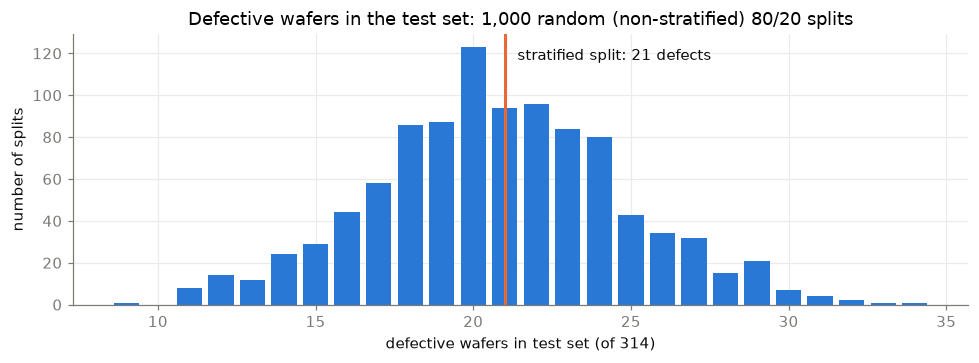

Random splits: 9-34 defects in test (95% of splits between 13 and 29), i.e. a test defect rate of 4.1% to 9.2%.


In [8]:
test_defects = np.array([
    train_test_split(y, test_size=TEST_SIZE, random_state=seed)[1].sum() for seed in range(1000)
])
expected = y.sum() * TEST_SIZE
fig, ax = plt.subplots(figsize=(9, 3.4))
values, freq = np.unique(test_defects, return_counts=True)
ax.bar(values, freq, color=BLUE, width=0.8)
ax.axvline(round(expected), color=ORANGE, lw=2)
ax.text(round(expected) + 0.4, freq.max() * 0.95, f"stratified split: {round(expected)} defects",
        color=INK)
ax.set(title="Defective wafers in the test set: 1,000 random (non-stratified) 80/20 splits",
       xlabel="defective wafers in test set (of 314)", ylabel="number of splits")
savefig(fig, "02_random_vs_stratified_split.png")
low, high = np.percentile(test_defects, [2.5, 97.5])
print(f"Random splits: {test_defects.min()}-{test_defects.max()} defects in test "
      f"(95% of splits between {low:.0f} and {high:.0f}), i.e. a test defect rate of "
      f"{low / 314:.1%} to {high / 314:.1%}.")

### 4.3 Implementation: stratified 80/20 split by defect status

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
)

def describe_split(name, target):
    return {"dataset": name, "wafers": len(target), "good (0)": int((target == 0).sum()),
            "defective (1)": int(target.sum()), "defective %": round(target.mean() * 100, 3),
            "share of all wafers %": round(len(target) / len(y) * 100, 1)}

split_table = pd.DataFrame([describe_split("original", y), describe_split("train", y_train),
                            describe_split("test", y_test)])
display(split_table.style.hide(axis="index"))

gap_train = abs(y_train.mean() - y.mean()) * 100
gap_test = abs(y_test.mean() - y.mean()) * 100
assert gap_train < 0.1 and gap_test < 0.1, "stratification failed"
assert X_train.index.intersection(X_test.index).empty, "train and test overlap"
print(f"Defect-rate deviation from original: train {gap_train:.3f} pp, test {gap_test:.3f} pp")
print("The remaining tiny gap is unavoidable: 104 x 0.2 = 20.8 defective wafers cannot be split exactly.")

dataset,wafers,good (0),defective (1),defective %,share of all wafers %
original,1567,1463,104,6.637000,100.000000
train,1253,1170,83,6.624000,80.000000
test,314,293,21,6.688000,20.000000


Defect-rate deviation from original: train 0.013 pp, test 0.051 pp
The remaining tiny gap is unavoidable: 104 x 0.2 = 20.8 defective wafers cannot be split exactly.


### 4.4 Put the test set aside: DO NOT TOUCH IT

The test set is written once to `data/processed/test_holdout.csv` together with a
SHA-256 fingerprint (`.sha256`). At final evaluation the fingerprint proves the file was
never modified. The variables are then **deleted** from this notebook. From here on,
everything uses the training set only.

In [10]:
test_hash = save_split(X_test, y_test, PROCESSED / "test_holdout.csv", seal=True)
train_hash = save_split(X_train, y_train, PROCESSED / "train_raw.csv")
print(f"test_holdout.csv  sealed, sha256 {test_hash[:16]}...  ({len(X_test)} rows)")
print(f"train_raw.csv     sha256 {train_hash[:16]}...  ({len(X_train)} rows)")

del X_test, y_test, X, y            # nothing from the test set remains in memory
assert "X_test" not in globals() and "y_test" not in globals()
print("Test set removed from memory. Only X_train / y_train are used from here on.")

test_holdout.csv  sealed, sha256 f2a9d0248b2cc8ee...  (314 rows)
train_raw.csv     sha256 10c997519a31f314...  (1253 rows)
Test set removed from memory. Only X_train / y_train are used from here on.


## 5. Rough feature reduction (training set only)

### 5.1 Constant features: variance exactly zero

A column that takes the same value for every wafer can't distinguish good from defective
wafers. We compute the variance per column (NaN-aware: missing values are ignored, not
treated as 0) and remove the columns whose variance is **exactly 0**. Columns with a
tiny but non-zero variance are **kept** in this step.

columns: 590   variance exactly 0: 116   variance undefined (<2 observed values): 0
smallest non-zero variance: 1.102e-08   (kept, because it is not exactly 0)


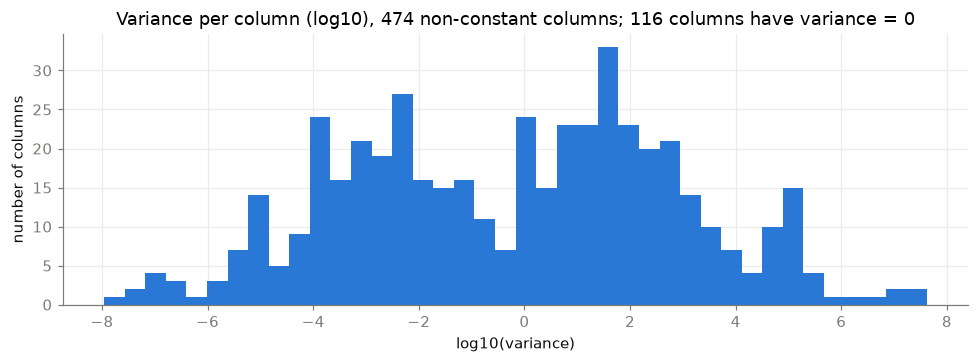

zero-variance columns: 005, 013, 042, 049, 052, 069, 097, 141, 149, 178, 179, 186, 189, 190, 191, 192, 193, 194, 226, 229, 230, 231, 232, 233, 234, 235, 236, 237, 240, 241, 242, 243, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 276, 284, 313, 314, 315, 322, 325, 326, 327, 328, 329, 330, 364, 369, 370, 371, 372, 373, 374, 375, 378, 379, 380, 381, 394, 395, 396, 397, 398, 399, 400, 401, 402, 403, 404, 414, 422, 449, 450, 451, 458, 461, 462, 463, 464, 465, 466, 481, 498, 501, 502, 503, 504, 505, 506, 507, 508, 509, 512, 513, 514, 515, 528, 529, 530, 531, 532, 533, 534, 535, 536, 537, 538


In [11]:
variance, zero_var_cols = zero_variance_features(X_train)
n_before = X_train.shape[1]
print(f"columns: {n_before}   variance exactly 0: {len(zero_var_cols)}   "
      f"variance undefined (<2 observed values): {int(variance.isna().sum())}")
nonzero = variance[variance > 0]
print(f"smallest non-zero variance: {nonzero.min():.3e}   (kept, because it is not exactly 0)")

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.hist(np.log10(nonzero), bins=40, color=BLUE)
ax.set(title=f"Variance per column (log10), {len(nonzero)} non-constant columns; "
             f"{len(zero_var_cols)} columns have variance = 0",
       xlabel="log10(variance)", ylabel="number of columns")
savefig(fig, "03_variance_per_column.png")
print("zero-variance columns:", ", ".join(c.replace("feature_", "") for c in zero_var_cols))

In [12]:
X_train_1 = X_train.drop(columns=zero_var_cols)
n_after_constant = X_train_1.shape[1]
print(f"{n_before} -> {n_after_constant} columns ({len(zero_var_cols)} removed)")

display(sip_table([
    ("Remove columns with variance exactly 0",
     "+ They carry no information at all; removal is lossless.\n"
     "+ Objective rule; no tuning.\n- None for these columns.",
     "CHOSEN",
     f"{n_before} -> {n_after_constant} columns ({len(zero_var_cols)} removed, "
     f"{len(zero_var_cols) / n_before:.1%})."),
    ("Also remove near-constant columns (variance below a small cut-off)",
     "+ Removes more weak columns.\n- Arbitrary cut-off; variance depends on the unit/scale, "
     "so a small variance is not the same as low information.\n- A rare deviation can be "
     "exactly the defect signal.",
     "Not chosen",
     "Smallest remaining variance is " f"{nonzero.min():.2e}; "
     "such columns are reviewed later by feature selection."),
    ("Keep all columns",
     "+ No risk of losing information.\n- Constant columns add dimensionality, cost and "
     "noise for imputation and models.",
     "Not chosen", "-"),
]))

590 -> 474 columns (116 removed)


Options / approaches,Pro and con,Decision made,Consequence
Remove columns with variance exactly 0,+ They carry no information at all; removal is lossless. + Objective rule; no tuning. - None for these columns.,CHOSEN,"590 -> 474 columns (116 removed, 19.7%)."
Also remove near-constant columns (variance below a small cut-off),"+ Removes more weak columns. - Arbitrary cut-off; variance depends on the unit/scale, so a small variance is not the same as low information. - A rare deviation can be exactly the defect signal.",Not chosen,Smallest remaining variance is 1.10e-08; such columns are reviewed later by feature selection.
Keep all columns,"+ No risk of losing information. - Constant columns add dimensionality, cost and noise for imputation and models.",Not chosen,-


### 5.2 Features with many N/As

Next, the columns that do have values but too many of them are missing. We compute the
missing percentage per remaining column and use two diagrams to choose a threshold:

1. **Diagram 1:** missing percentage per column, with columns sorted from most to least
   missing. Plateaus show groups of columns that go missing together, and gaps show
   natural cut points.
2. **Diagram 2 (Pareto):** for every possible threshold (x), the number of columns that
   would be removed (y).

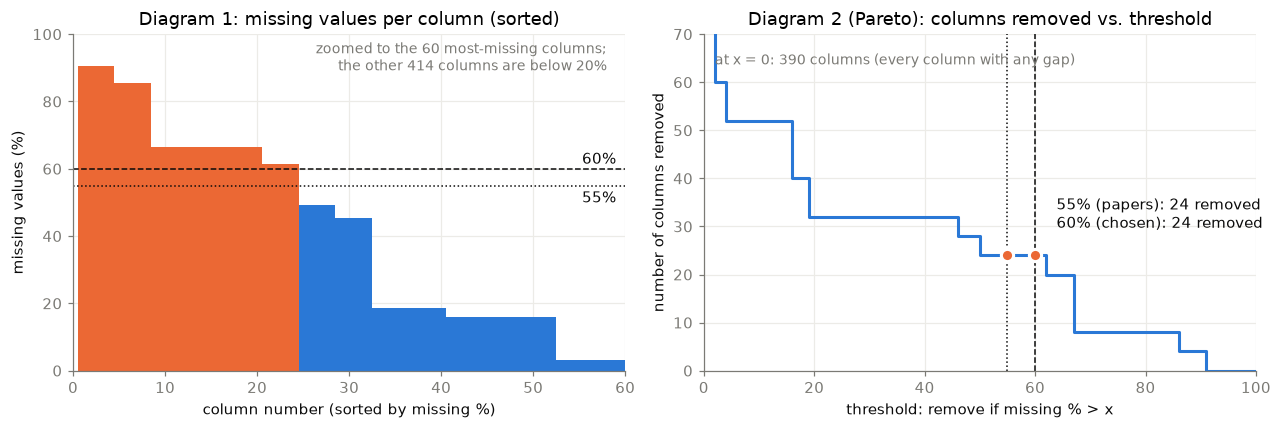

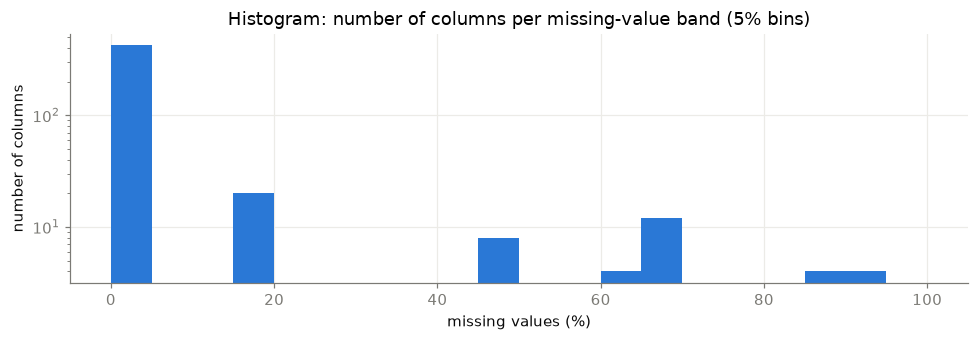

In [13]:
missing_pct = missing_percentage(X_train_1)
pareto = missing_threshold_pareto(missing_pct)
PAPER_THRESHOLD, THRESHOLD = 55, 60

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ordered = missing_pct.sort_values(ascending=False).reset_index(drop=True)
removed_mask = ordered > THRESHOLD
axes[0].bar(ordered.index + 1, ordered, width=1.0,
            color=np.where(removed_mask, ORANGE, BLUE))
for t, style in ((PAPER_THRESHOLD, ":"), (THRESHOLD, "--")):
    axes[0].axhline(t, color=INK, ls=style, lw=1)
    axes[0].text(59, t + (1.5 if t == THRESHOLD else -5), f"{t}%", ha="right", color=INK)
axes[0].set(title="Diagram 1: missing values per column (sorted)",
            xlabel="column number (sorted by missing %)", ylabel="missing values (%)",
            xlim=(0, len(ordered) + 1), ylim=(0, 100))
axes[0].set_xlim(0, 60)
axes[0].text(58, 98, "zoomed to the 60 most-missing columns;\n"
             f"the other {len(ordered) - 60} columns are below 20%", ha="right", va="top",
             color=MUTED, fontsize=9)

axes[1].step(pareto["threshold_pct"], pareto["columns_removed"], where="post", color=BLUE, lw=2)
n_at = {t: int(pareto.loc[pareto["threshold_pct"] == t, "columns_removed"].iloc[0])
        for t in (PAPER_THRESHOLD, THRESHOLD)}
for t, style in ((PAPER_THRESHOLD, ":"), (THRESHOLD, "--")):
    axes[1].axvline(t, color=INK, ls=style, lw=1)
    axes[1].plot(t, n_at[t], "o", color=ORANGE, ms=8, mec="white", mew=2, zorder=3)
axes[1].annotate(f"55% (papers): {n_at[PAPER_THRESHOLD]} removed\n"
                 f"60% (chosen): {n_at[THRESHOLD]} removed",
                 (THRESHOLD, n_at[THRESHOLD]), xytext=(14, 18), textcoords="offset points",
                 color=INK)
axes[1].set(title="Diagram 2 (Pareto): columns removed vs. threshold",
            xlabel="threshold: remove if missing % > x", ylabel="number of columns removed",
            xlim=(0, 100))
axes[1].set_ylim(0, 70)
axes[1].text(2, 66, f"at x = 0: {int(pareto['columns_removed'].iloc[0])} columns "
             "(every column with any gap)", color=MUTED, fontsize=9, va="top")
savefig(fig, "04_missing_values_threshold.png")

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.hist(missing_pct, bins=np.arange(0, 105, 5), color=BLUE)
ax.set(title="Histogram: number of columns per missing-value band (5% bins)",
       xlabel="missing values (%)", ylabel="number of columns")
ax.set_yscale("log")
savefig(fig, "05_missing_values_histogram.png")

In [14]:
levels = (missing_pct[missing_pct > 20].round(1).value_counts().sort_index()
          .rename_axis("missing %").rename("columns").to_frame())
display(levels.T)
candidate = pareto[pareto["threshold_pct"].isin([20, 40, 45, 50, 55, 60, 65, 70, 80, 90])]
display(candidate.set_index("threshold_pct").T)
gap_low = missing_pct[missing_pct <= THRESHOLD].max()
gap_high = missing_pct[missing_pct > THRESHOLD].min()
print(f"No column has a missing % between {gap_low:.1f}% and {gap_high:.1f}%: "
      f"every threshold in that range removes the same columns.")

missing %,45.3,49.1,61.3,66.3,85.6,90.7
columns,4,4,4,12,4,4


threshold_pct,20,40,45,50,55,60,65,70,80,90
columns_removed,32,32,32,24,24,24,20,8,8,4
columns_kept,442,442,442,450,450,450,454,466,466,470


No column has a missing % between 49.1% and 61.3%: every threshold in that range removes the same columns.


**Reading the diagrams**
- **Diagram 1.** Missingness comes in **plateaus**: groups of 4–12 columns with exactly
  the same missing % (45.3%, 49.1%, 61.3%, 66.3%, 85.6% and 90.7%). These are sensor
  groups that go offline together. The natural cut points are the **gaps between
  plateaus**, and the widest gap of interest lies **between 49.1% and 61.3%**.
- **Diagram 2.** The removal curve is a staircase. It is flat across the whole 49.1–61.3%
  gap, so **55% (papers) and 60% (our start) remove exactly the same 24 columns**. The
  choice inside the gap is not sensitive. Going below 49.1% would also remove the 49.1%
  group (8 columns), whose missingness is associated with the defect rate (logged in the
  diary as D-009). Going above 61.3% would keep columns where we would have to invent
  more than 60% of the values.
- **Threshold: 60%.** Remove columns with missing % > 60.

In [15]:
high_missing_cols = missing_pct.index[missing_pct > THRESHOLD].tolist()
X_train_2 = X_train_1.drop(columns=high_missing_cols)
n_after_missing = X_train_2.shape[1]
cells_before = int(X_train_1.isna().sum().sum())
cells_after = int(X_train_2.isna().sum().sum())
print(f"{n_after_constant} -> {n_after_missing} columns ({len(high_missing_cols)} removed)")
print(f"missing cells: {cells_before:,} -> {cells_after:,} "
      f"({X_train_1.isna().mean().mean():.2%} -> {X_train_2.isna().mean().mean():.2%} of cells)")
print("removed:", ", ".join(c.replace("feature_", "") for c in high_missing_cols))

removed_at = lambda t: int(pareto.loc[pareto["threshold_pct"] == t, "columns_removed"].iloc[0])
display(sip_table([
    ("Threshold 55% (as in the papers)",
     "+ Literature value, comparable with published SECOM work.\n"
     "- On this training set identical to 60%; no extra effect.",
     "Not chosen (same result)", f"would remove {removed_at(55)} columns"),
    ("Threshold 60% (course starting point)",
     "+ Sits in the natural gap between plateaus (49.1% -> 61.3%), so it is not sensitive.\n"
     "+ Keeps the 45-49% groups, including the group whose missingness carries defect "
     "information.\n- Kept columns may still be ~49% missing, so imputation has to carry "
     "them.",
     "CHOSEN",
     f"{n_after_constant} -> {n_after_missing} columns ({len(high_missing_cols)} removed); "
     f"missing cells {cells_before:,} -> {cells_after:,}. Cumulative: {n_before} -> "
     f"{n_after_missing} ({n_before - n_after_missing} removed)."),
    ("Lower threshold (e.g. 40-45%)",
     "+ Less imputation needed.\n- Removes the 45.3% and 49.1% groups (8 more columns), "
     "including informative missingness.",
     "Not chosen", f"would remove {removed_at(40)} columns"),
    ("Higher threshold (e.g. 70-80%) or keep all",
     "+ Keeps every signal.\n- The imputer would invent 60-90% of a column's values; "
     "imputed values dominate the real ones.",
     "Not chosen", f"70%: would remove {removed_at(70)} columns"),
    ("Drop rows with missing values instead",
     "- Impossible: no wafer is complete; every row would be deleted.",
     "Not chosen", "-"),
]))

474 -> 450 columns (24 removed)
missing cells: 33,091 -> 11,211 (5.57% -> 1.99% of cells)
removed: 085, 109, 110, 111, 157, 158, 220, 244, 245, 246, 292, 293, 358, 382, 383, 384, 492, 516, 517, 518, 578, 579, 580, 581


Options / approaches,Pro and con,Decision made,Consequence
Threshold 55% (as in the papers),"+ Literature value, comparable with published SECOM work. - On this training set identical to 60%; no extra effect.",Not chosen (same result),would remove 24 columns
Threshold 60% (course starting point),"+ Sits in the natural gap between plateaus (49.1% -> 61.3%), so it is not sensitive. + Keeps the 45-49% groups, including the group whose missingness carries defect information. - Kept columns may still be ~49% missing, so imputation has to carry them.",CHOSEN,"474 -> 450 columns (24 removed); missing cells 33,091 -> 11,211. Cumulative: 590 -> 450 (140 removed)."
Lower threshold (e.g. 40-45%),"+ Less imputation needed. - Removes the 45.3% and 49.1% groups (8 more columns), including informative missingness.",Not chosen,would remove 32 columns
Higher threshold (e.g. 70-80%) or keep all,+ Keeps every signal. - The imputer would invent 60-90% of a column's values; imputed values dominate the real ones.,Not chosen,70%: would remove 8 columns
Drop rows with missing values instead,- Impossible: no wafer is complete; every row would be deleted.,Not chosen,-


## 6. Correlation between features (visualise only)

Papers often remove one feature from each pair with |r| > 0.8. **We don't do that yet.**
Which feature of a correlated pair is more valuable is unknown, so the removal would come
down to a random choice. A better, model-based method (Boruta feature selection) comes
later. Here we only **look** at the redundancy.

The heatmap orders the columns by hierarchical clustering on 1 − |r|, so blocks of
redundant sensors appear as squares along the diagonal. Correlations are computed
pairwise, using only the wafers where both values are present.

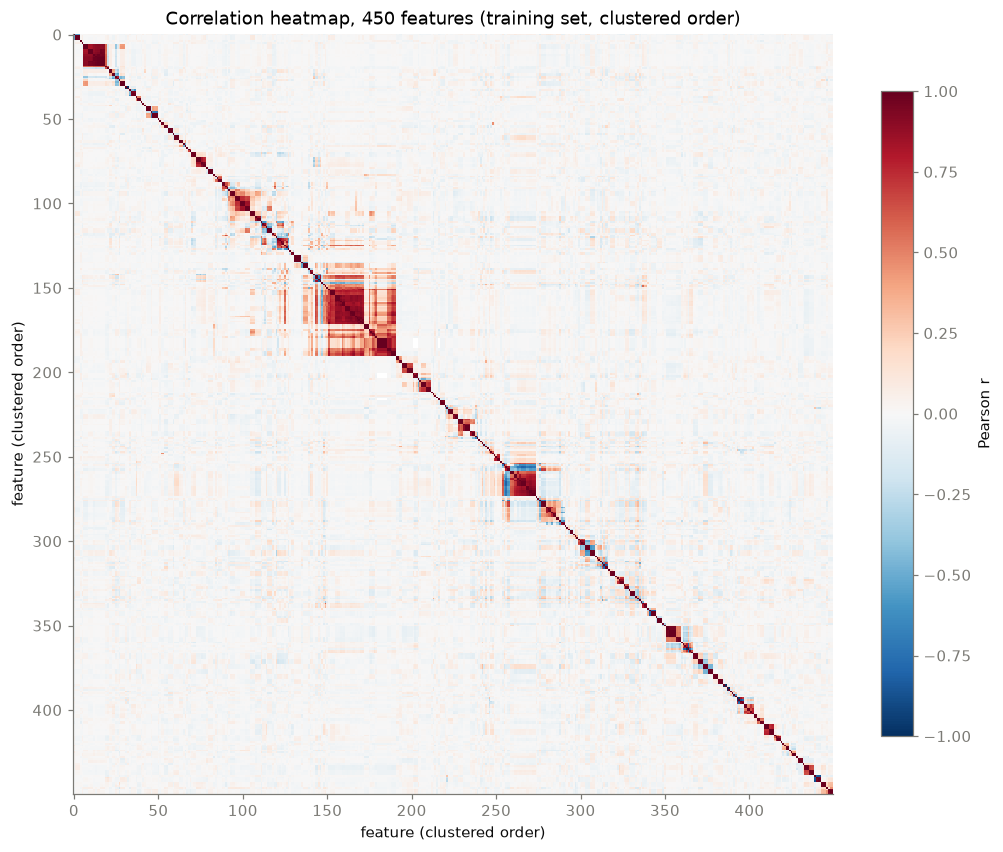

,value
feature pairs,101001
pairs with |r| > 0.8,608
pairs with |r| > 0.9,371
pairs with |r| > 0.9999 (practically identical),26
features involved in at least one |r| > 0.8 pair,335
median |r| over all pairs,0.024


In [16]:
corr = X_train_2.corr()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().dropna()
filled = corr.fillna(0).to_numpy(copy=True)
np.fill_diagonal(filled, 1.0)
distance = np.clip(1 - np.abs(filled), 0, None)
order = leaves_list(linkage(squareform(distance, checks=False), method="average"))
ordered_corr = corr.iloc[order, order]

fig, ax = plt.subplots(figsize=(9.5, 8))
image = ax.imshow(ordered_corr, cmap="RdBu_r", vmin=-1, vmax=1, interpolation="nearest")
ax.set(title=f"Correlation heatmap, {corr.shape[0]} features (training set, clustered order)",
       xlabel="feature (clustered order)", ylabel="feature (clustered order)")
ax.grid(False)
fig.colorbar(image, ax=ax, shrink=0.8, label="Pearson r")
savefig(fig, "06_correlation_heatmap.png")

strong = upper[upper.abs() > 0.8]
involved = set(strong.index.get_level_values(0)) | set(strong.index.get_level_values(1))
summary = pd.Series({
    "feature pairs": len(upper),
    "pairs with |r| > 0.8": len(strong),
    "pairs with |r| > 0.9": int((upper.abs() > 0.9).sum()),
    "pairs with |r| > 0.9999 (practically identical)": int((upper.abs() > 0.9999).sum()),
    "features involved in at least one |r| > 0.8 pair": len(involved),
    "median |r| over all pairs": round(float(upper.abs().median()), 3),
}, name="value", dtype=object)
display(summary.to_frame())

In [17]:
display(sip_table([
    ("Remove one feature of every pair with |r| > 0.8",
     "+ Shrinks redundancy quickly; common in papers.\n- Which feature to keep is a random "
     "choice; we may drop the informative one.\n- Pairwise rule ignores multi-feature "
     "blocks.",
     "Not chosen (now)", f"would affect {len(involved)} of {corr.shape[0]} features"),
    ("Visualise only; defer removal to model-based feature selection (Boruta)",
     "+ No information lost on a random choice.\n+ Redundancy is documented and can "
     "inform imputation (correlated features help MICE/KNN).\n- More features to carry "
     "through imputation.",
     "CHOSEN",
     f"No columns removed; {corr.shape[0]} features remain. {len(strong)} pairs with "
     f"|r| > 0.8 noted for later."),
    ("PCA / feature extraction",
     "+ Removes redundancy without picking.\n- Components are no longer sensors; this "
     "defeats the goal of identifying key signals.",
     "Not chosen", "-"),
]))

Options / approaches,Pro and con,Decision made,Consequence
Remove one feature of every pair with |r| > 0.8,+ Shrinks redundancy quickly; common in papers. - Which feature to keep is a random choice; we may drop the informative one. - Pairwise rule ignores multi-feature blocks.,Not chosen (now),would affect 335 of 450 features
Visualise only; defer removal to model-based feature selection (Boruta),+ No information lost on a random choice. + Redundancy is documented and can inform imputation (correlated features help MICE/KNN). - More features to carry through imputation.,CHOSEN,No columns removed; 450 features remain. 608 pairs with |r| > 0.8 noted for later.
PCA / feature extraction,+ Removes redundancy without picking. - Components are no longer sensors; this defeats the goal of identifying key signals.,Not chosen,-


## 7. Outliers: 3σ rule

**Identification.** A value counts as an outlier when it lies outside
**mean ± 3 · standard deviation** of its column. Mean and standard deviation are computed
on the **training set**, ignoring missing values. Missing values are never flagged. (An
IQR approach is deliberately **not** used.)

In [18]:
bounds = three_sigma_bounds(X_train_2, k=3.0)
is_outlier = flag_outliers(X_train_2, bounds)
observed = int(X_train_2.notna().sum().sum())
outlier_cells = int(is_outlier.sum().sum())
per_col = is_outlier.sum()
per_row = is_outlier.sum(axis=1)

outlier_overview = pd.Series({
    "observed values": observed,
    "outlier values (3σ)": outlier_cells,
    "outlier share of observed values %": round(outlier_cells / observed * 100, 3),
    "columns with at least one outlier": int(per_col.gt(0).sum()),
    "max outliers in one column": int(per_col.max()),
    "wafers with at least one outlier": int(per_row.gt(0).sum()),
    "wafers with at least one outlier %": round(per_row.gt(0).mean() * 100, 1),
}, name="value", dtype=object)
display(outlier_overview.to_frame())

,value
observed values,552639
outlier values (3σ),4872
outlier share of observed values %,0.882
columns with at least one outlier,412
max outliers in one column,61
wafers with at least one outlier,1008
wafers with at least one outlier %,80.4


**Do outliers carry the defect signal?** This matters for the decision. If defective
wafers tend to have more extreme values, deleting those values would delete exactly what
we're looking for.

,wafers,defect_rate
1 outliers,449,4.90
2 outliers,187,5.88
3-5 outliers,323,7.74
6-52 outliers,294,8.50


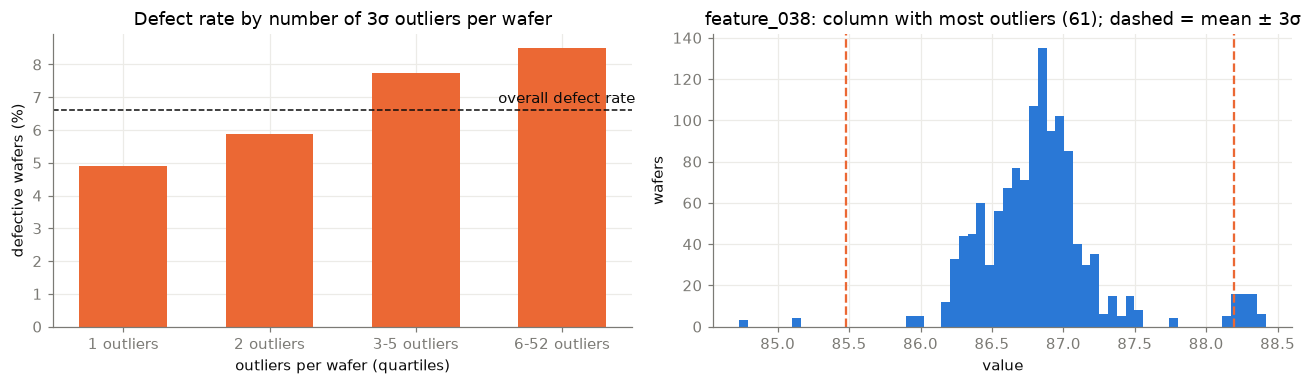

In [19]:
quartile = pd.qcut(per_row, 4, duplicates="drop")
signal = y_train.groupby(quartile, observed=True).agg(wafers="size", defect_rate="mean")
signal["defect_rate"] = (signal["defect_rate"] * 100).round(2)
def _label(interval):
    low, high = max(int(interval.left) + 1, 0), int(interval.right)
    return f"{low} outliers" if low == high else f"{low}-{high} outliers"
signal.index = [_label(i) for i in signal.index]
display(signal)

example = per_col.idxmax()
values = X_train_2[example].dropna()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].bar(signal.index, signal["defect_rate"], color=ORANGE, width=0.6)
axes[0].axhline(y_train.mean() * 100, color=INK, ls="--", lw=1)
axes[0].text(len(signal) - 0.5, y_train.mean() * 100 + 0.2, "overall defect rate",
             ha="right", color=INK)
axes[0].set(title="Defect rate by number of 3σ outliers per wafer",
            ylabel="defective wafers (%)", xlabel="outliers per wafer (quartiles)")
axes[1].hist(values, bins=60, color=BLUE)
for edge in ("lower", "upper"):
    axes[1].axvline(bounds.loc[example, edge], color=ORANGE, ls="--", lw=1.5)
axes[1].set(title=f"{example}: column with most outliers ({int(per_col.max())}); "
                  "dashed = mean ± 3σ",
            xlabel="value", ylabel="wafers")
savefig(fig, "07_outliers_3sigma.png")

**Three options for treating outliers**

1. **Do nothing:** keep the extreme values as they are.
2. **Substitute by the 3σ boundary (capping / winsorising):** replace a value above
   mean + 3σ by mean + 3σ, and one below mean − 3σ by mean − 3σ.
3. **Remove and leave gaps:** set the outlier to NaN and let the imputer fill it later.

The cell below computes the consequences of each option on the training set.

In [20]:
X_cap = cap_outliers(X_train_2, bounds)
X_gap = remove_outliers(X_train_2, bounds)
std_before = X_train_2.std()
compare = pd.DataFrame({
    "values changed": [0, outlier_cells, outlier_cells],
    "missing cells afterwards": [int(X_train_2.isna().sum().sum()),
                                 int(X_cap.isna().sum().sum()), int(X_gap.isna().sum().sum())],
    "median change of column std %": [0.0,
        round(float(((X_cap.std() - std_before) / std_before).median() * 100), 2),
        round(float(((X_gap.std() - std_before) / std_before).median() * 100), 2)],
    "largest |z| remaining": [
        round(float(((X_train_2 - bounds["mean"]) / bounds["std"]).abs().max().max()), 1),
        round(float(((X_cap - bounds["mean"]) / bounds["std"]).abs().max().max()), 1),
        round(float(((X_gap - bounds["mean"]) / bounds["std"]).abs().max().max()), 1)],
}, index=["1 do nothing", "2 cap at 3σ boundary", "3 remove (leave gaps)"])
display(compare)

,values changed,missing cells afterwards,median change of column std %,largest |z| remaining
1 do nothing,0,11211,0.00,35.4
2 cap at 3σ boundary,4872,11211,-12.89,3.0
3 remove (leave gaps),4872,16083,-19.96,3.0


**Decision: option 2, substitute by the 3σ boundary (capping).**

- **It keeps the signal.** The defect rate rises with the number of outliers per wafer
  (table above). Capping keeps the information that "this wafer is extreme in this sensor":
  the value stays at the edge of the distribution, on the correct side.
- **It avoids inventing data.** Option 3 would add one new gap for every outlier (see the
  table), turning measured values into values an imputer has to guess. That runs against
  everything we did to reduce missingness in Section 5.
- **It tames scale-sensitive steps.** Option 1 would leave values far outside the bulk.
  Those dominate the mean and standard deviation that KNN/MICE imputation, scaling and
  SMOTE rely on.
- **Caveats.** (a) The 3σ rule assumes a roughly symmetric distribution, and many columns
  are skewed, so on the long side of a skewed column it flags more values. (b) The bounds
  are fitted once on the training set and stored. They will be **re-used unchanged** on
  the test set, never re-estimated on it. (c) We cap once. Recomputing 3σ after capping
  would shrink the bounds and flag new values indefinitely.

In [21]:
X_train_3 = X_cap
assert int(X_train_3.isna().sum().sum()) == int(X_train_2.isna().sum().sum()), "capping changed NaNs"
assert not flag_outliers(X_train_3, bounds).any().any(), "values outside bounds remain"

display(sip_table([
    ("1  Do nothing",
     "+ No information changed.\n- Extreme values distort mean/std, scaling, distance-based "
     "imputation (KNN, MICE) and SMOTE.",
     "Not chosen", f"{outlier_cells:,} extreme values would stay"),
    ("2  Substitute by the 3σ boundary (capping)",
     "+ Keeps the wafer's 'extreme' direction (outlier count is associated with defects).\n"
     "+ Adds no missing values.\n+ Bounds are stored and re-applied to the test set.\n"
     "- Compresses the tails; ties at the boundary.\n- 3σ is asymmetric-unaware on skewed "
     "columns.",
     "CHOSEN",
     f"{outlier_cells:,} values capped ({outlier_cells / observed:.2%} of observed) in "
     f"{int(per_col.gt(0).sum())} columns, {int(per_row.gt(0).sum())} wafers; missing cells "
     f"unchanged at {int(X_train_3.isna().sum().sum()):,}; columns stay {X_train_3.shape[1]}."),
    ("3  Remove and leave gaps (NaN)",
     "+ Imputer can choose a plausible value.\n- Turns measured values into missing ones; "
     "discards the extreme-value signal.",
     "Not chosen",
     f"missing cells would rise {int(X_train_2.isna().sum().sum()):,} -> "
     f"{int(X_gap.isna().sum().sum()):,}"),
]))

Options / approaches,Pro and con,Decision made,Consequence
1 Do nothing,"+ No information changed. - Extreme values distort mean/std, scaling, distance-based imputation (KNN, MICE) and SMOTE.",Not chosen,"4,872 extreme values would stay"
2 Substitute by the 3σ boundary (capping),+ Keeps the wafer's 'extreme' direction (outlier count is associated with defects). + Adds no missing values. + Bounds are stored and re-applied to the test set. - Compresses the tails; ties at the boundary. - 3σ is asymmetric-unaware on skewed columns.,CHOSEN,"4,872 values capped (0.88% of observed) in 412 columns, 1008 wafers; missing cells unchanged at 11,211; columns stay 450."
3 Remove and leave gaps (NaN),+ Imputer can choose a plausible value. - Turns measured values into missing ones; discards the extreme-value signal.,Not chosen,"missing cells would rise 11,211 -> 16,083"


## 8. Summary and saved state

In [22]:
funnel = pd.DataFrame([
    ("raw training set", X_train.shape[1], int(X_train.isna().sum().sum()), "-"),
    ("5.1 remove variance = 0", X_train_1.shape[1], int(X_train_1.isna().sum().sum()),
     f"-{len(zero_var_cols)} columns"),
    (f"5.2 remove missing > {THRESHOLD}%", X_train_2.shape[1], int(X_train_2.isna().sum().sum()),
     f"-{len(high_missing_cols)} columns"),
    ("6 correlation (visualise only)", X_train_2.shape[1], int(X_train_2.isna().sum().sum()),
     "no change"),
    ("7 cap 3σ outliers", X_train_3.shape[1], int(X_train_3.isna().sum().sum()),
     f"{outlier_cells:,} values capped"),
], columns=["step", "columns", "missing cells", "change"])
display(funnel.style.hide(axis="index"))
print(f"Training wafers throughout: {len(X_train_3):,} ({int(y_train.sum())} defective, "
      f"{y_train.mean():.2%})")

save_split(X_train_2, y_train, PROCESSED / "train_reduced.csv")
save_split(X_train_3, y_train, PROCESSED / "train_prepared.csv")
bounds.to_csv(PROCESSED / "three_sigma_bounds.csv", float_format="%.10g")
save_state(PROCESSED / "preparation_state.json", {
    "random_state": RANDOM_STATE, "test_size": TEST_SIZE,
    "test_holdout_sha256": test_hash,
    "zero_variance_columns": zero_var_cols,
    "missing_threshold_pct": THRESHOLD,
    "high_missing_columns": high_missing_cols,
    "kept_columns": X_train_3.columns.tolist(),
    "outlier_rule": "mean +/- 3 std on training set; values capped at the bound",
    "outlier_bounds_file": "three_sigma_bounds.csv",
})
print("saved: train_reduced.csv, train_prepared.csv, three_sigma_bounds.csv, "
      "preparation_state.json")
print("test hold-out unchanged since sealing:", verify_sealed(PROCESSED / "test_holdout.csv"))

step,columns,missing cells,change
raw training set,590,33868,-
5.1 remove variance = 0,474,33091,-116 columns
5.2 remove missing > 60%,450,11211,-24 columns
6 correlation (visualise only),450,11211,no change
7 cap 3σ outliers,450,11211,"4,872 values capped"


Training wafers throughout: 1,253 (83 defective, 6.62%)


saved: train_reduced.csv, train_prepared.csv, three_sigma_bounds.csv, preparation_state.json
test hold-out unchanged since sealing: True


**State after this notebook**

| | Value |
|---|---|
| Training wafers | 1,253 (83 defective, 6.62%) |
| Test wafers | 314, sealed in `data/processed/test_holdout.csv`, **not touched** |
| Features | 590 → 474 (variance = 0) → **450** (missing > 60%) |
| Correlation | Visualised; nothing removed (deferred to Boruta) |
| Outliers | 3σ capping; bounds saved for the test set |
| Still missing | ~2% of training cells → **next step: imputation** (candidates in diary entry D-010) |

To apply the same preparation to the test set at final evaluation: drop `zero_variance_columns`
and `high_missing_columns` from `preparation_state.json`, then clip with
`three_sigma_bounds.csv`. Never refit any of these on the test data.